# Figure 13.1 — Generation, recombination, and excess-carrier transport

Carrier lifetime controls temporal decay, diffusion length controls spatial decay, and quasi-Fermi-level splitting measures departure from equilibrium.

## Direct NumPy calculation

The governing relations are evaluated explicitly before the reusable course implementation is imported.

diffusion length = 44.721 micrometers
largest quasi-Fermi splitting = 0.8377 eV


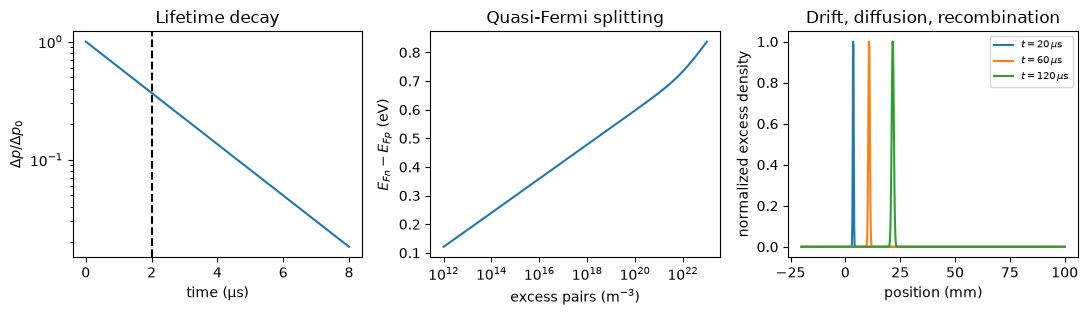

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
from scipy.sparse import eye, lil_matrix
from scipy.sparse.linalg import spsolve

q = 1.602_176_634e-19
k_B = 1.380_649e-23
T = 300.0
V_T = k_B * T / q
n_i = 9.65e15
n_0 = 1.0e22
p_0 = n_i**2 / n_0
tau = 2.0e-6
D = 1.0e-3
L = np.sqrt(D * tau)

time = np.linspace(0.0, 8.0e-6, 500)
delta_0 = 2.0e20
delta_t = delta_0 * np.exp(-time / tau)
assert np.isclose(delta_t[np.argmin(abs(time-tau))] / delta_0, np.exp(-1), rtol=0.01)

excess = np.logspace(12.0, 23.0, 500)
n = n_0 + excess
p = p_0 + excess
splitting = V_T * np.log(n * p / n_i**2)
assert splitting[0] >= 0.0 and np.all(np.diff(splitting) > 0.0)

position = np.linspace(-0.02, 0.10, 700)
v_d = 180.0
fig, axes = plt.subplots(1, 3, figsize=(11.0, 3.25))
axes[0].semilogy(time * 1e6, delta_t / delta_0)
axes[0].axvline(tau * 1e6, ls="--", color="black")
axes[0].set(xlabel="time (µs)", ylabel=r"$\Delta p/\Delta p_0$", title="Lifetime decay")
axes[1].semilogx(excess, splitting)
axes[1].set(xlabel=r"excess pairs (m$^{-3}$)", ylabel=r"$E_{Fn}-E_{Fp}$ (eV)", title="Quasi-Fermi splitting")
for pulse_time in (20e-6, 60e-6, 120e-6):
    packet = np.exp(-(position-v_d*pulse_time)**2/(4*D*pulse_time)-pulse_time/(180e-6)) / np.sqrt(4*np.pi*D*pulse_time)
    packet /= np.max(packet)
    axes[2].plot(position * 1e3, packet, label=fr"$t={pulse_time*1e6:.0f}\,\mu$s")
axes[2].set(xlabel="position (mm)", ylabel="normalized excess density", title="Drift, diffusion, recombination")
axes[2].legend(fontsize=7)
print(f"diffusion length = {L*1e6:.3f} micrometers")
print(f"largest quasi-Fermi splitting = {splitting[-1]:.4f} eV")
fig.tight_layout()
plt.show()

## Finite-difference continuity and center kinetics

The numerical model now tests three reductions used in Chapter 13:

1. a periodic drift–diffusion–recombination packet against the analytic Haynes–Shockley solution;
2. a nonlinear steady SRH boundary-value problem with a surface-recombination condition; and
3. the full dynamic center-occupancy equation against the algebraic steady-occupancy SRH rate.

In [2]:
# Periodic grid and smooth initial packet.
x_fd = np.linspace(-0.012, 0.012, 481, endpoint=False)
t_fd = np.linspace(0.0, 40.0e-6, 81)
dx = x_fd[1] - x_fd[0]
D_fd, v_fd, tau_fd = 8.0e-4, 150.0, 80.0e-6
x_initial, sigma_initial = -4.0e-3, 0.8e-3
packet_initial = np.exp(-0.5*((x_fd-x_initial)/sigma_initial)**2)

# Assemble D*d2/dx2 - v*d/dx - 1/tau with centered diffusion and
# second-order upwind drift. Periodic indexing removes contact artifacts.
point_count = x_fd.size
operator = lil_matrix((point_count, point_count), dtype=float)
diffusion_weight = D_fd/dx**2
drift_weight = abs(v_fd)/dx
for i in range(point_count):
    operator[i, i] = -2*diffusion_weight - 1.5*drift_weight - 1/tau_fd
    operator[i, (i-1) % point_count] += diffusion_weight + 2*drift_weight
    operator[i, (i+1) % point_count] += diffusion_weight
    operator[i, (i-2) % point_count] -= 0.5*drift_weight
operator = operator.tocsr()
identity = eye(point_count, format="csr")

# Crank–Nicolson time stepping.
packet_fd = np.empty((t_fd.size, point_count))
packet_fd[0] = packet_initial
for step, dt in enumerate(np.diff(t_fd), start=1):
    lhs = identity - 0.5*dt*operator
    rhs = (identity + 0.5*dt*operator) @ packet_fd[step-1]
    packet_fd[step] = spsolve(lhs, rhs)

# Infinite-domain analytic result for the same finite-width Gaussian.
elapsed = t_fd[-1]
variance = sigma_initial**2 + 2*D_fd*elapsed
packet_exact = sigma_initial/np.sqrt(variance) * np.exp(
    -0.5*(x_fd-x_initial-v_fd*elapsed)**2/variance - elapsed/tau_fd
)
packet_relative_l2 = np.linalg.norm(packet_fd[-1]-packet_exact)/np.linalg.norm(packet_exact)
particle_ratio = packet_fd[-1].sum()/packet_fd[0].sum()
assert packet_relative_l2 < 0.01
assert np.isclose(particle_ratio, np.exp(-elapsed/tau_fd), rtol=3e-5)
print(f"packet relative L2 error = {packet_relative_l2:.4e}")
print(f"integrated-packet ratio = {particle_ratio:.7f}")

packet relative L2 error = 4.9987e-03
integrated-packet ratio = 0.6065297


In [3]:
# Nonlinear steady state: D*Delta'' + G(x) - U_SRH(Delta) = 0.
x_bvp = np.linspace(0.0, 200.0e-6, 181)
dx_bvp = x_bvp[1] - x_bvp[0]
D_bvp, S_bvp = 1.0e-3, 100.0
G_bvp = 5.0e25*np.exp(-x_bvp/(40.0e-6))
ni_bvp, n0_bvp = 1.0e16, 1.0e21
p0_bvp = ni_bvp**2/n0_bvp
tau_n_bvp = tau_p_bvp = 2.0e-6
nB_bvp = pB_bvp = ni_bvp
scale_bvp = G_bvp.max()*tau_p_bvp

def srh_rate_direct(excess):
    electron = n0_bvp + excess
    hole = p0_bvp + excess
    return (electron*hole-ni_bvp**2) / (
        tau_p_bvp*(electron+nB_bvp) + tau_n_bvp*(hole+pB_bvp)
    )

def bvp_residual(excess):
    residual = np.empty_like(excess)
    residual[1:-1] = (
        excess[:-2]-2*excess[1:-1]+excess[2:]
        + dx_bvp**2/D_bvp*(G_bvp[1:-1]-srh_rate_direct(excess)[1:-1])
    )
    # D*dDelta/dx = S*Delta at the left surface; Delta=0 at the right contact.
    residual[0] = excess[1]-excess[0]-S_bvp*dx_bvp/D_bvp*excess[0]
    residual[-1] = excess[-1]
    return residual/scale_bvp

initial_bvp = np.linspace(scale_bvp, 0.0, x_bvp.size)
bvp_solution = least_squares(
    bvp_residual, initial_bvp, bounds=(0.0, np.inf),
    xtol=1e-11, ftol=1e-11, gtol=1e-11, max_nfev=4000,
)
assert bvp_solution.success
excess_bvp = bvp_solution.x
bvp_max_residual = np.max(abs(bvp_residual(excess_bvp)))
assert bvp_max_residual < 2e-6
print(f"nonlinear BVP normalized residual = {bvp_max_residual:.3e}")

nonlinear BVP normalized residual = 8.412e-10


In [4]:
# Dynamic center occupancy during and after a short generation pulse.
t_kinetic = np.linspace(0.0, 8.0e-6, 401)
n0_k, p0_k = 1.0e21, 1.0e11
Nt_k = 2.0e20
alpha_n, alpha_p = 5.0e-15, 2.0e-14
nB_k = pB_k = 1.0e16
G_pulse, pulse_end = 2.0e26, 0.6e-6
F0_k = (alpha_n*n0_k + alpha_p*pB_k) / (
    alpha_n*(n0_k+nB_k) + alpha_p*(p0_k+pB_k)
)

def center_rates(n, p, F):
    U_n = Nt_k*alpha_n*(n*(1-F)-nB_k*F)
    U_p = Nt_k*alpha_p*(p*F-pB_k*(1-F))
    return U_n, U_p

def center_rhs(time, state):
    n, p, F = state
    U_n, U_p = center_rates(n, p, F)
    generation = G_pulse if time < pulse_end else 0.0
    return generation-U_n, generation-U_p, (U_n-U_p)/Nt_k

kinetic = solve_ivp(
    center_rhs, (t_kinetic[0], t_kinetic[-1]), (n0_k, p0_k, F0_k),
    method="BDF", t_eval=t_kinetic, rtol=2e-8,
    atol=(1e4, 1e4, 1e-10), max_step=np.diff(t_kinetic).min(),
)
assert kinetic.success
n_k, p_k, F_k = kinetic.y
U_n_k, U_p_k = center_rates(n_k, p_k, F_k)
tau_n_k, tau_p_k = 1/(Nt_k*alpha_n), 1/(Nt_k*alpha_p)
U_qs_k = (n_k*p_k-nB_k*pB_k) / (
    tau_p_k*(n_k+nB_k) + tau_n_k*(p_k+pB_k)
)
charge_invariant = p_k-n_k-Nt_k*F_k
invariant_drift = np.ptp(charge_invariant)/abs(charge_invariant[0])
assert invariant_drift < 1e-9
assert np.all((F_k >= 0) & (F_k <= 1))
print(f"charge-invariant relative drift = {invariant_drift:.3e}")

charge-invariant relative drift = 2.318e-12


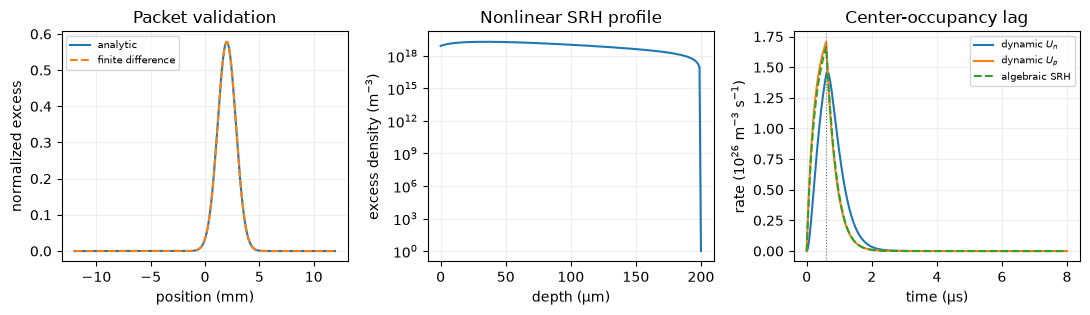

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11.0, 3.25))
axes[0].plot(x_fd*1e3, packet_exact, label="analytic")
axes[0].plot(x_fd*1e3, packet_fd[-1], "--", label="finite difference")
axes[0].set(xlabel="position (mm)", ylabel="normalized excess", title="Packet validation")
axes[0].legend(fontsize=7)

axes[1].semilogy(x_bvp*1e6, np.maximum(excess_bvp, 1.0))
axes[1].set(xlabel="depth (µm)", ylabel=r"excess density (m$^{-3}$)", title="Nonlinear SRH profile")

rate_scale = 1e26
axes[2].plot(t_kinetic*1e6, U_n_k/rate_scale, label=r"dynamic $U_n$")
axes[2].plot(t_kinetic*1e6, U_p_k/rate_scale, label=r"dynamic $U_p$")
axes[2].plot(t_kinetic*1e6, U_qs_k/rate_scale, "--", label="algebraic SRH")
axes[2].axvline(pulse_end*1e6, color="0.4", ls=":", lw=0.8)
axes[2].set(xlabel="time (µs)", ylabel=r"rate ($10^{26}$ m$^{-3}$ s$^{-1}$)", title="Center-occupancy lag")
axes[2].legend(fontsize=7)
for axis in axes: axis.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Reusable publication implementation

The tested course implementation writes the deterministic PDF used by the manuscript.

In [6]:
import sys
from pathlib import Path

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "main.tex").exists()
)
sys.path.insert(0, str(ROOT / "figures" / "src"))

from semphy.transport_extensions import (
    continuity_numerics_figure,
    nonequilibrium_carriers_figure,
)

nonequilibrium_carriers_figure()
continuity_numerics_figure()
print("wrote transport-nonequilibrium-carriers.pdf")
print("wrote transport-continuity-numerics.pdf")

wrote transport-nonequilibrium-carriers.pdf
wrote transport-continuity-numerics.pdf
